# アテンションの重みをヒートマップで可視化する

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/11_transformers/attention_viz.ipynb)

NLP クックブック 11-09 ／ Transformers の基本操作

Transformer の自己注意が、どのトークンからどのトークンに向いているのかを図で見たい。

In [1]:
import torch
from transformers import AutoModel, AutoTokenizer

name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(name, attn_implementation="eager").eval()   # 重みを取り出すには eager 実装が必要

text = "The animal didn't cross the street because it was too tired."
enc = tokenizer(text, return_tensors="pt")
with torch.no_grad():
    attentions = model(**enc, output_attentions=True).attentions
tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
print(len(attentions), "層", attentions[0].shape, "= (バッチ, ヘッド, トークン, トークン)")

12 層 torch.Size([1, 12, 16, 16]) = (バッチ, ヘッド, トークン, トークン)


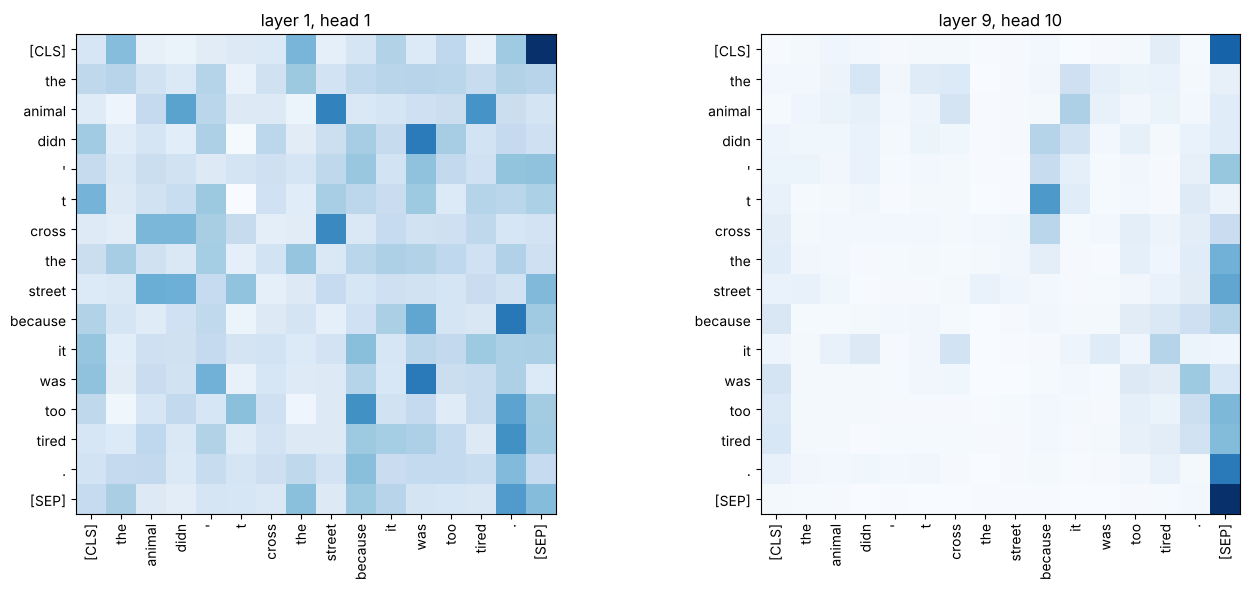

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (layer, head) in zip(axes, [(0, 0), (8, 9)]):
    ax.imshow(attentions[layer][0, head], cmap="Blues")
    ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens)
    ax.set_title(f"layer {layer + 1}, head {head + 1}")
plt.tight_layout(); plt.show()

In [3]:
# 「it」がどのトークンに注意を向けているか、全層・全ヘッドの平均と、最も強く向いているヘッド
it = tokens.index("it")
stacked = torch.stack(attentions)[:, 0]                 # (層, ヘッド, トークン, トークン)
avg = stacked[:, :, it].mean(dim=(0, 1))
print("平均:", [(tokens[i], round(avg[i].item(), 2)) for i in avg.argsort(descending=True)[:5]])
animal = tokens.index("animal")
layer, head = divmod(stacked[:, :, it, animal].argmax().item(), stacked.shape[1])
print(f"it → animal が最大のヘッド: layer {layer + 1}, head {head + 1} ({stacked[layer, head, it, animal]:.2f})")

平均: [('[SEP]', 0.25), ('[CLS]', 0.1), ('animal', 0.09), ('.', 0.08), ('because', 0.08)]
it → animal が最大のヘッド: layer 4, head 11 (0.85)


- 行が「注意を向ける側」、列が「向けられる側」。各行の和は 1。
- 下位層は隣接トークンや `[SEP]` に向くヘッドが多く、中〜上位層に構文関係や共参照に対応するヘッドが現れる。
- アテンションの重みは、そのまま「モデルの判断根拠」ではない。説明として使うときは注意が必要 (Jain & Wallace, 2019)。